# Исследовательский анализ данных и проверка гипотез 
Автор: Гребнева Мария Андреевна  
Дата: 18.09.2026

### Цель  
Выявить инсайты об изменении пользовательских предпочтений и популярности событий осенью 2024 года, а также проверить гипотезы о различиях в поведении пользователей мобильных и стационарных устройств.

### Описание данных

Первый датасет final_tickets_orders_df.csv включает информацию обо всех заказах билетов, совершённых с двух типов устройств — мобильных и стационарных. Поля датасета соответствуют таблице purchases:

order_id — уникальный идентификатор заказа  
user_id — уникальный идентификатор пользователя  
created_dt_msk — дата создания заказа (московское время)  
created_ts_msk — дата и время создания заказа (московское время)  
event_id — идентификатор мероприятия из таблицы events  
cinema_circuit — сеть кинотеатров. Если не применимо, то здесь будет значение 'нет'  
age_limit — возрастное ограничение мероприятия  
currency_code — валюта оплаты, например rub для российских рублей  
device_type_canonical — тип устройства, с которого был оформлен заказ    
revenue — выручка от заказа  
service_name — название билетного оператора  
tickets_count — количество купленных билетов  
total — общая сумма заказа  
days_since_prev — количество дней с предыдущей покупки для каждого пользователя. Если покупки не было, то данные содержат пропуск.

Второй датасет final_tickets_events_df содержит информацию о событиях, включая город и регион события, а также информацию о площадке проведения мероприятия.Датасет содержит такие поля:

event_id — уникальный идентификатор мероприятия  
event_name — название мероприятия  
event_type_description — описание типа мероприятия  
event_type_main — основной тип мероприятия: театральная постановка, концерт и так далее  
organizers — организаторы мероприятия  
region_name — название региона  
city_name — название города  
venue_id — уникальный идентификатор площадки  
venue_name — название площадки  
venue_address — адрес площадки  

Датасет final_tickets_tenge_df.csv с информацией о курсе тенге к российскому рублю за 2024 год. Значения в рублях представлено для 100 тенге. Датасет содержит такие поля:

nominal — номинал (100 тенге)  
data — дата  
curs — курс тенге к рублю  
cdx — обозначение валюты (kzt)

### Содержание проекта

1. Загрузить и изучить данные о бронированиях билетов за июнь–октябрь 2024 года.
2. Провести предобработку: обработать пропуски, дубликаты, выбросы, привести валюты к рублю, создать новые признаки.
3. Провести исследовательский анализ:
 - распределение заказов по сегментам и сезонные изменения;
 - осенняя активность пользователей (динамика по дням, недельная цикличность);
 - популярные события, регионы и партнёры.
4. Проверить статистические гипотезы о различиях между мобильными и стационарными пользователями.
5. Сформулировать выводы и рекомендации для продуктовой команды.

## 1. Загрузка данных и знакомство с ними

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import ttest_rel, mannwhitneyu

In [3]:
orders = pd.read_csv('/datasets/final_tickets_orders_df.csv')

In [3]:
display(orders.info())
display(orders.head())
display(orders.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(3), int64(4), object(7)
m

None

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,Край билетов,4,10870.99,NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,Мой билет,2,2067.51,NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,За билетом!,4,13984.16,75.0
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,Лови билет!,2,212.28,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,Билеты без проблем,3,10695.43,83.0


order_id                     0
user_id                      0
created_dt_msk               0
created_ts_msk               0
event_id                     0
cinema_circuit               0
age_limit                    0
currency_code                0
device_type_canonical        0
revenue                      0
service_name                 0
tickets_count                0
total                        0
days_since_prev          21940
dtype: int64

Необходимо изменить тип данных: created_dt_msk и created_ts_msk хранятся как object → datetime

In [4]:
events = pd.read_csv('/datasets/final_tickets_events_df.csv')

In [5]:
display(events.info())
display(events.head())
display(events.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


None

,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"


event_id                  0
event_name                0
event_type_description    0
event_type_main           0
organizers                0
region_name               0
city_name                 0
city_id                   0
venue_id                  0
venue_name                0
venue_address             0
dtype: int64

Данные датасета корректностны и соответствуют описанию.

In [6]:
tenge = pd.read_csv('/datasets/final_tickets_tenge_df.csv')

In [7]:
display(tenge.info())
display(tenge.head())
display(tenge.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


None

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


data       0
nominal    0
curs       0
cdx        0
dtype: int64

Необходимо изменить тип данных в поле 'data': object → datetime

Данные загружены корректно: три датасета соответствуют описанию, структура и объём совпадают с ожиданиями. Пропуски обнаружены только в days_since_prev — это логично, поскольку для первых заказов пользователей предыдущей покупки не существует.

На этапе предобработки предстоит:

привести выручку к единой валюте (рубли), используя датасет с курсом тенге;

убедиться, что пропуски в days_since_prev действительно относятся только к первым заказам пользователей, и обосновать решение оставить их как есть;

проверить данные на полные и неполные дубликаты;

проверить категориальные признаки (cinema_circuit, currency_code, device_type_canonical, service_name, event_type_main, region_name, age_limit) на неявные дубликаты — разный регистр, разный формат записи, опечатки, значения-заглушки;

проверить количественные признаки (revenue, tickets_count, total, days_since_prev) на невалидные значения и аномалии;

опционально сменить типы данных на более компактные, чтобы снизить объём занимаемой памяти.

## Предобработка данных и подготовка их к исследованию

Кроме столбца days_since_prev, данные не содержат пропусков. имся, что пропуски имеются только у первых заказов

days_since_prev = NaN, если у пользователя нет предыдущего заказа.
Значит, для каждого пользователя:

первый по времени заказ должен иметь days_since_prev = NaN;

все последующие заказы — заполнены.

Проверим это по каждому user_id.

In [8]:
first = orders.sort_values('created_ts_msk').groupby('user_id').head(1)

display('Пропуски у первых заказов:', first['days_since_prev'].isna().sum(), 'из', len(first))
display('Пропуски у остальных заказов:', orders.drop(first.index)['days_since_prev'].isna().sum())

'Пропуски у первых заказов:'

18487

'из'

21940

'Пропуски у остальных заказов:'

3453

Пропуски в days_since_prev в основном относятся к первым заказам пользователей (18 487 из 21 940), что логично. Однако у 3 453 строк пропуски есть и у непервых заказов — это требует пояснения. Возможные причины: несколько заказов в один день, особая логика расчёта интервалов или неполнота данных. Решение: оставляем как есть, поскольку для анализа пауз эти строки не критичны

Изменим тип данных, где это необходимо:

In [9]:
orders['created_dt_msk'] = pd.to_datetime(orders['created_dt_msk'])
orders['created_ts_msk'] = pd.to_datetime(orders['created_ts_msk'])

In [10]:
tenge['data'] = pd.to_datetime(tenge['data'])

Проверка ключей на дубликаты

In [11]:
display(
    f"orders: уникальный идентификатор заказа event_id = {orders['event_id'].nunique()} из {len(orders)}",
    f"events: дубликатов event_id = {events['event_id'].duplicated().sum()}",
    f"events: уник. event_id = {events['event_id'].nunique()} из {len(events)}",
    f"tenge: дубликатов data = {tenge['data'].duplicated().sum()}",
    f"tenge: уник. data = {tenge['data'].nunique()} из {len(tenge)}"
)

'orders: уникальный идентификатор заказа event_id = 22446 из 290849'

'events: дубликатов event_id = 0'

'events: уник. event_id = 22427 из 22427'

'tenge: дубликатов data = 0'

'tenge: уник. data = 357 из 357'

Нет дубликатов, но event_id  в таблице заказов больше на 19, чем в таблице мероприятий, оставим их тк вероятно, эти события — фильмы, исключённые из events по условию задачи, тк их не так много. Их вклад в общие метрики (число заказов, выручка) сохраним, но в разрезе по регионам и типам мероприятий они не учтутся — это не искажает выводы.

Проверим, адекватные ли значения курса в таблице tenge и на все ли даты есть курс

In [12]:
tenge['nominal'].unique()

array([100])

In [13]:
display(tenge['curs'].describe(percentiles=[.01, .25, .5, .75, .95, .99]))

display('curs <= 0:', (tenge['curs'] <= 0).sum())
display('curs > 50:', (tenge['curs'] > 50).sum())
display('curs < 10:', (tenge['curs'] < 10).sum())

count    357.000000
mean      19.755818
std        0.833798
min       17.848600
1%        18.020472
25%       19.120200
50%       19.876000
75%       20.443300
95%       20.894880
99%       21.008436
max       21.937100
Name: curs, dtype: float64

'curs <= 0:'

0

'curs > 50:'

0

'curs < 10:'

0

count = 357 - нет дат без курса (весь год заполнен)
Аномалий нет: нулевых, отрицательных, экстремально низких (<10) и высоких (>50) значений — 0
Адекватность значений: курс варьируется в диапазоне 17–21 руб. за 100 тенге, среднее — 19,76. Это соответствует реальному курсу тенге к рублю

In [14]:
order_dates = set(orders['created_dt_msk'].dt.normalize().unique())
tenge_dates = set(tenge['data'].dt.normalize().unique())
missing = order_dates - tenge_dates

display('Дат заказов без курса:', len(missing))
if missing:
    display('Примеры:', sorted(missing)[:5])

'Дат заказов без курса:'

0

Для категориальных значений проверим, какие категории присутствуют в данных, встречаются ли значения, которые могут обозначать пропуски в данных или отсутствие информации. Проведем нормализацию данных, если это необходимо

In [15]:
cat_cols = ['cinema_circuit', 'currency_code', 'device_type_canonical',
            'service_name', 'age_limit']

for col in cat_cols:
    display(orders[col].value_counts(dropna=False))

нет           289451
Другое          1261
КиноСити         122
Киномакс           7
Москино            7
ЦентрФильм         1
Name: cinema_circuit, dtype: int64

rub    285780
kzt      5069
Name: currency_code, dtype: int64

mobile     232679
desktop     58170
Name: device_type_canonical, dtype: int64

Билеты без проблем        63709
Лови билет!               41126
Билеты в руки             40364
Мой билет                 34843
Облачко                   26642
Лучшие билеты             17795
Весь в билетах            16849
Прачечная                 10273
Край билетов               6207
Тебе билет!                5228
Яблоко                     5039
Дом культуры               4502
За билетом!                2865
Городской дом культуры     2733
Show_ticket                2200
Мир касс                   2167
Быстробилет                2003
Выступления.ру             1616
Восьмёрка                  1118
Crazy ticket!               790
Росбилет                    539
Шоу начинается!             499
Быстрый кассир              381
Радио ticket                376
Телебилет                   321
КарандашРУ                  133
Реестр                      125
Билет по телефону            85
Вперёд!                      80
Дырокол                      74
Кино билет                   67
Цвет и б

16    78579
12    62557
0     61487
6     52173
18    36053
Name: age_limit, dtype: int64

Все категории имеют ожидаемые значения

Можем объединить таблицы

In [16]:
df = orders.merge(events, on='event_id', how='left')
# добавляем курс тенге — даты в разных столбцах
df = df.merge(tenge, left_on='created_dt_msk', right_on='data', how='left')

# лишний столбец data убираем
df = df.drop(columns='data')

Проверим дубликаты: одинаковое содержание, разный order_id:

In [17]:
dup_cols = ['user_id', 'event_id', 'created_ts_msk', 'tickets_count', 'total']
n_dup = df.duplicated(subset=dup_cols).sum()
display('Неявных дубликатов (разный order_id):', n_dup)

'Неявных дубликатов (разный order_id):'

44

In [18]:
before = len(df)

df = df.drop_duplicates(subset=dup_cols, keep='first').copy()
display('Удалено дубликатов:', before - len(df))

df = df.sort_values(['user_id', 'created_ts_msk'])
df['days_since_prev'] = (
    df.groupby('user_id')['created_dt_msk'].diff().dt.days
)

'Удалено дубликатов:'

44

 Проверка event_type_main и region_name

In [19]:
for col in ['event_type_main', 'region_name', 'city_name']:
    display(df[col].value_counts(dropna=False).head(30))
    display('Уникальных:', df[col].nunique(), '| пропусков:', df[col].isna().sum())

концерты    115265
театр        67311
другое       65852
спорт        21904
стендап      13393
выставки      4853
ёлки          1989
NaN            238
Name: event_type_main, dtype: int64

'Уникальных:'

7

'| пропусков:'

238

Каменевский регион           91044
Североярская область         44042
Широковская область          16457
Медовская область            13896
Озернинский край             10476
Светополянский округ          7605
Малиновоярский округ          6617
Речиновская область           6292
Солнечноземская область       6287
Яблоневская область           6179
Серебринская область          5610
Горицветская область          5165
Травяная область              5045
Лугоградская область          4701
Тепляковская область          4387
Солнечнореченская область     3996
Зоринский регион              3214
Глиногорская область          3214
Шанырский регион              2881
Чистогорская область          2685
Лесодальний край              2577
Верхоречная область           2387
Заречная область              2160
Травиницкий округ             1779
Ветренский регион             1767
Боровлянский край             1721
Каменноозёрный край           1657
Речицкий регион               1590
Каменноярский край  

... (5 outputs left out)

'Уникальных:'

352

'| пропусков:'

238

Проверка event_type_main, region_name, city_name показала:

7 типов мероприятий — ожидаемые категории (концерты, театр, другое, спорт, стендап, выставки, ёлки);

81 регион и 352 города — все с осмысленными названиями;

238 пропусков в каждом из трёх столбцов — это заказы на 19 event_id, отсутствующих в справочнике events (вероятно, фильмы, исключённые по условию задачи);

неявных дубликатов нет — разный регистр, пробелы, опечатки не обнаружены.

Решение: оставить пропуски как есть

Доля таких заказов, на выводы не влияет.

Проверим тнеявные дубликаты: одинаковый order_id, разное содержание:

In [20]:
display((df.groupby('order_id').size() > 1).sum())

0

Для количественных значений посмотрим на распределение и наличие выбросов

Статистика по revenue и tickets_count раздельно по валютам

In [21]:
for cur in df['currency_code'].unique():
    sub = df[df['currency_code'] == cur]
    display(sub[['revenue', 'tickets_count']]
            .describe(percentiles=[.01, .25, .5, .75, .95, .99]))

,revenue,tickets_count
count,285737.000000,285737.000000
mean,547.587111,2.754075
std,871.558344,1.171406
min,-90.760000,1.000000
1%,0.000000,1.000000
25%,113.870000,2.000000
50%,346.180000,3.000000
75%,791.700000,4.000000
95%,1606.500000,5.000000
99%,2569.590000,6.000000


,revenue,tickets_count
count,5068.000000,5068.000000
mean,4995.827484,2.763220
std,4917.039292,1.115393
min,0.000000,1.000000
1%,90.270000,1.000000
25%,518.100000,2.000000
50%,3698.830000,3.000000
75%,7397.660000,4.000000
95%,13784.260000,5.000000
99%,17617.240000,6.000000


Обе валюты имеют правостороннее скошенное распределение выручки: среднее заметно выше медианы — большинство заказов недорогие, но единичные крупные чеки тянут среднее вверх.

Проблемы, требующие обработки:

отрицательная выручка в рублях (−90,76) — вероятно, возвраты;

очень крупные выбросы в рублях: max (81 174) в 30 раз выше 99-го перцентиля (2 570);

в тенге выбросы мягче, но тоже есть (max = 26 425 при 99% = 17 617).

Решение: удалить отрицательную выручку, отсечь выбросы revenue по 99-му перцентилю раздельно для rub и kzt

tickets_count — стабилен в обеих валютах: медиана 3, 99% заказов ≤ 6 билетов

После очистки распределения выручки станут компактнее, среднее приблизится к медиане — это обеспечит более корректный анализ сезонности, среднего чека и сравнения сегментов. 

Построим визуализации до и после отсечения выбросов по 99-му перцентилю

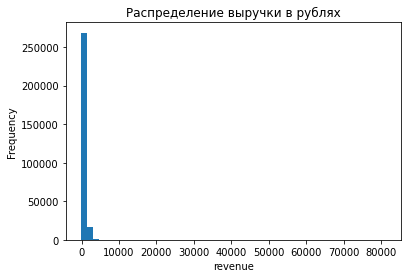

In [22]:
sub = df[df['currency_code'] == 'rub']
sub['revenue'].plot(kind='hist', bins=50, title='Распределение выручки в рублях')
plt.xlabel('revenue')
plt.show()

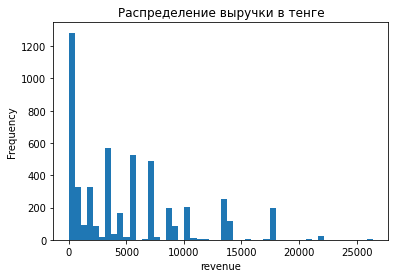

In [23]:
sub = df[df['currency_code'] == 'kzt']
sub['revenue'].plot(kind='hist', bins=50, title='Распределение выручки в тенге')
plt.xlabel('revenue')
plt.show()

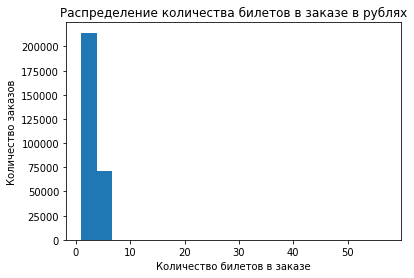

In [24]:
sub = df[df['currency_code'] == 'rub']

sub['tickets_count'].plot(kind='hist', bins=20, title='Распределение количества билетов в заказе в рублях')
plt.xlabel('Количество билетов в заказе')
plt.ylabel('Количество заказов')
plt.show()

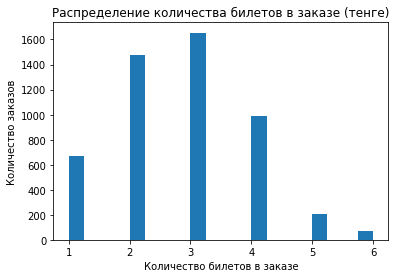

In [25]:
sub = df[df['currency_code'] == 'kzt']

sub['tickets_count'].plot(kind='hist', bins=20, title='Распределение количества билетов в заказе (тенге)')
plt.xlabel('Количество билетов в заказе')
plt.ylabel('Количество заказов')
plt.show()

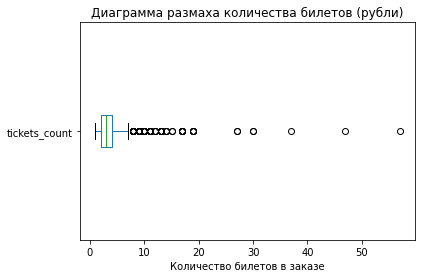

In [26]:
sub = df[df['currency_code'] == 'rub']

sub['tickets_count'].plot(kind='box', vert=False, title='Диаграмма размаха количества билетов (рубли)')
plt.xlabel('Количество билетов в заказе')
plt.show()

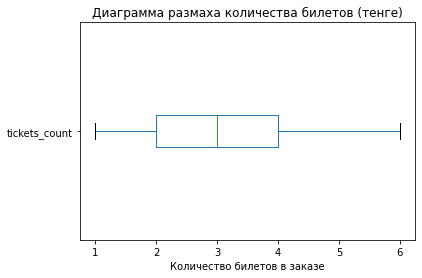

In [27]:
sub = df[df['currency_code'] == 'kzt']

sub['tickets_count'].plot(kind='box', vert=False, title='Диаграмма размаха количества билетов (тенге)')
plt.xlabel('Количество билетов в заказе')
plt.show()

Обе валюты имеют правостороннее скошенное распределение выручки, следовательно, среднее завышено относительно медианы
В рублях есть отрицательные значения и очень крупные выбросы — их нужно обработать

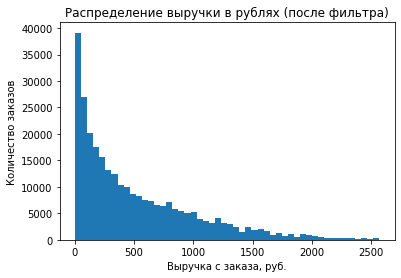

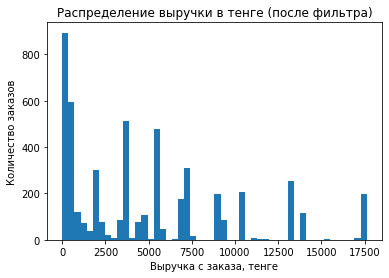

In [28]:
# 1. Убираем отрицательную выручку
df = df[df['revenue'] >= 0].copy()

# 2. Считаем 99-й перцентиль отдельно по валютам
rub_q = df.loc[df['currency_code'] == 'rub', 'revenue'].quantile(0.99)
kzt_q = df.loc[df['currency_code'] == 'kzt', 'revenue'].quantile(0.99)

# 3. Отсекаем выбросы revenue по 99-му перцентилю внутри каждой валюты
df = df[
    ((df['currency_code'] == 'rub') & (df['revenue'] <= rub_q)) |
    ((df['currency_code'] == 'kzt') & (df['revenue'] <= kzt_q))
].copy()

# 4. Визуальная проверка — rub
sub = df[df['currency_code'] == 'rub']
sub['revenue'].plot(kind='hist', bins=50,
                    title='Распределение выручки в рублях (после фильтра)')
plt.xlabel('Выручка с заказа, руб.')
plt.ylabel('Количество заказов')
plt.show()

# 5. Визуальная проверка — kzt
sub = df[df['currency_code'] == 'kzt']
sub['revenue'].plot(kind='hist', bins=50,
                    title='Распределение выручки в тенге (после фильтра)')
plt.xlabel('Выручка с заказа, тенге')
plt.ylabel('Количество заказов')
plt.show()

Новое поле revenue_rub — выручка с заказа в единой валюте — российский рубль

In [29]:
# курс за 1 тенге в рублях (в исходнике — за 100 тенге)
tenge['rate_rub_per_kzt'] = tenge['curs'] / tenge['nominal']

# оставляем только нужные столбцы и переименовываем дату под orders
tenge_small = (tenge[['data', 'rate_rub_per_kzt']]
               .rename(columns={'data': 'created_dt_msk'}))

display(tenge_small.head())

# присоединяем курс
df = df.merge(tenge_small, on='created_dt_msk', how='left')

# revenue_rub через .where()
df['revenue_rub'] = df['revenue'].where(df['currency_code'] == 'rub', df['revenue'] * df['curs'] / 100)

,created_dt_msk,rate_rub_per_kzt
0,2024-01-10,0.199391
1,2024-01-11,0.197255
2,2024-01-12,0.195839
3,2024-01-13,0.194501
4,2024-01-14,0.194501


Новое поле month — месяц оформления заказа

In [30]:
df['month'] = df['created_dt_msk'].dt.month

Новое поле season — создайте столбец с информацией о сезонности

In [31]:
season_map = {12:'зима',1:'зима',2:'зима',
              3:'весна',4:'весна',5:'весна',
              6:'лето',7:'лето',8:'лето',
              9:'осень',10:'осень',11:'осень'}
df['season'] = df['month'].map(season_map)
df['season'].value_counts()

осень    168437
лето     119159
Name: season, dtype: int64

Данные очищены от аномалий и дубликатов, приведены к единой валюте (рубли), обогащены признаками для сезонного анализа. Потерь минимум (≈2–3% строк), структура сохранена. Датасет готов к исследовательскому анализу.

## Исследовательский анализ данных

### Анализ распределения заказов по сегментам и их сезонные изменения

На дашборде было замечено, что осенью число заказов растёт, но средний чек снижается. В этом разделе проверяю, подтверждается ли этот паттерн в данных и за счёт каких сегментов происходят изменения: по типам мероприятий, устройствам и возрастному рейтингу.

season,лето,осень,изм_%
event_type_main,,,
стендап,215.22,228.67,6.25
выставки,89.53,93.46,4.39
другое,82.67,82.51,-0.19
спорт,50.69,49.85,-1.65
концерты,302.76,269.67,-10.93
театр,211.35,176.36,-16.56
ёлки,263.50,217.97,-17.28


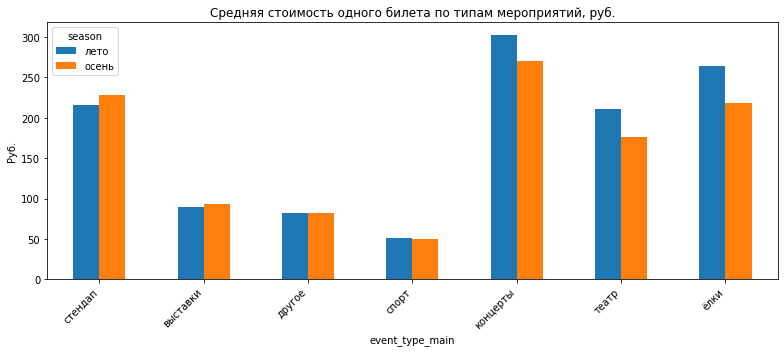

In [32]:
avg = (df[df['season'].isin(['лето', 'осень'])]
       .groupby(['event_type_main', 'season'])
       .agg(revenue_sum=('revenue_rub', 'sum'),
            tickets_sum=('tickets_count', 'sum')))

avg['avg_ticket'] = avg['revenue_sum'] / avg['tickets_sum']
avg = avg['avg_ticket'].unstack()

avg['изм_%'] = (avg['осень'] - avg['лето']) / avg['лето'] * 100
avg = avg.sort_values('изм_%', ascending=False)

display(avg.round(2))

avg[['лето', 'осень']].plot(kind='bar', figsize=(11, 5),
    title='Средняя стоимость одного билета по типам мероприятий, руб.')
plt.ylabel('Руб.')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Рост числа заказов осенью идёт за счёт более дешёвых покупок внутри популярных категорий, а не за счёт общего роста цен.

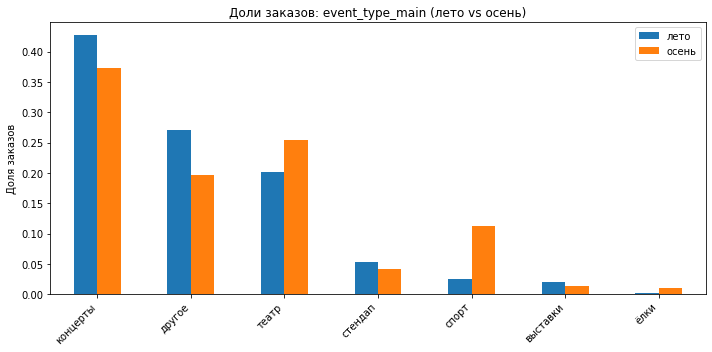

,лето,осень
концерты,0.426809,0.372502
другое,0.270760,0.196366
театр,0.201298,0.253736
стендап,0.053353,0.041107
спорт,0.025247,0.111985
выставки,0.020237,0.014262
ёлки,0.002295,0.010041


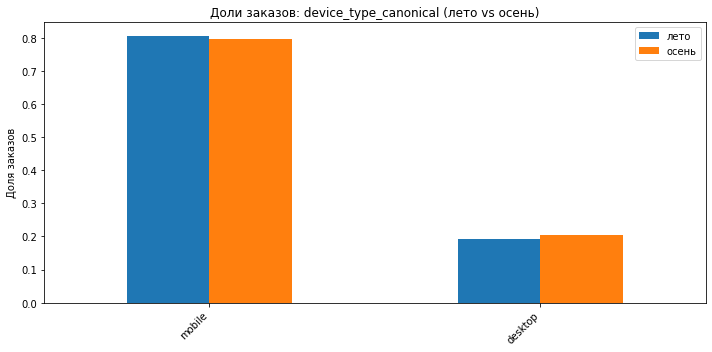

,лето,осень
mobile,0.806217,0.796387
desktop,0.193783,0.203613


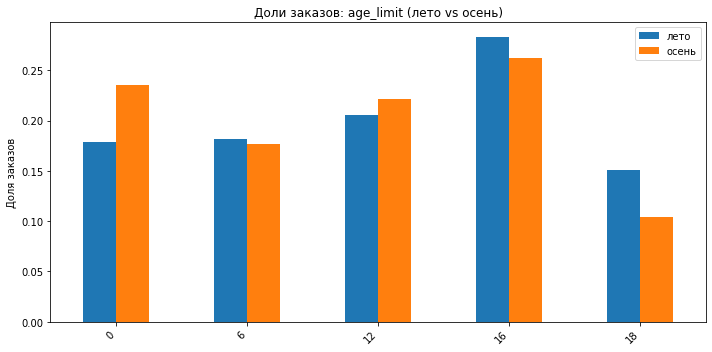

,лето,осень
0,0.178518,0.235732
6,0.181866,0.176220
12,0.205582,0.221293
16,0.283462,0.262466
18,0.150572,0.104288


In [33]:
summer = df[df['season'] == 'лето']
autumn = df[df['season'] == 'осень']

def shares(sub, col):
    return sub[col].value_counts(normalize=True).rename('share')

for col in ['event_type_main', 'device_type_canonical', 'age_limit']:
    comp = pd.concat([
        shares(summer, col).rename('лето'),
        shares(autumn, col).rename('осень')
    ], axis=1).fillna(0)

    comp.plot(kind='bar', figsize=(10, 5),
              title=f'Доли заказов: {col} (лето vs осень)')
    plt.ylabel('Доля заказов')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    display(comp)

Спорт — точка роста. Резкий скачок доли говорит о хорошем отклике. Стоит усилить маркетинг и заключить партнёрства с клубами/лигами.

Театр — сезонный драйвер осени. Момент для премьер.

Семейный сегмент растёт — осенью имеет смысл усиливать предложения для родителей с детьми (0+, 6+).

Mobile (80%) — основной канал. Вложения в мобильный сценарий дадут максимальный эффект независимо от сезона.


### Осенняя активность пользователей

In [34]:
autumn = df[df['season'] == 'осень'].copy()
print('Осенних заказов:', len(autumn))
print('Период:', autumn['created_dt_msk'].min().date(), '—',
      autumn['created_dt_msk'].max().date())

Осенних заказов: 168437
Период: 2024-09-01 — 2024-10-31


In [35]:
# цена одного билета
df['one_ticket_price_rub'] = (
    df['total'].where(
        df['currency_code'] == 'rub',
        df['total'] * df['rate_rub_per_kzt']
    ) / df['tickets_count']
)

# осень
autumn = df[df['season'] == 'осень'].copy()
autumn['date'] = autumn['created_dt_msk'].dt.date

# Сводная по дням
daily = autumn.groupby('date').agg(
    orders=('order_id', 'count'),
    dau=('user_id', 'nunique'),
    avg_ticket=('one_ticket_price_rub', 'mean')
)
daily['orders_per_user'] = daily['orders'] / daily['dau']

display(daily.head())

,orders,dau,avg_ticket,orders_per_user
date,,,,
2024-09-01,1327,564,2290.044165,2.352837
2024-09-02,1376,573,2198.632156,2.401396
2024-09-03,5094,777,1300.835280,6.555985
2024-09-04,1761,684,2172.382109,2.574561
2024-09-05,1941,738,2196.142791,2.630081


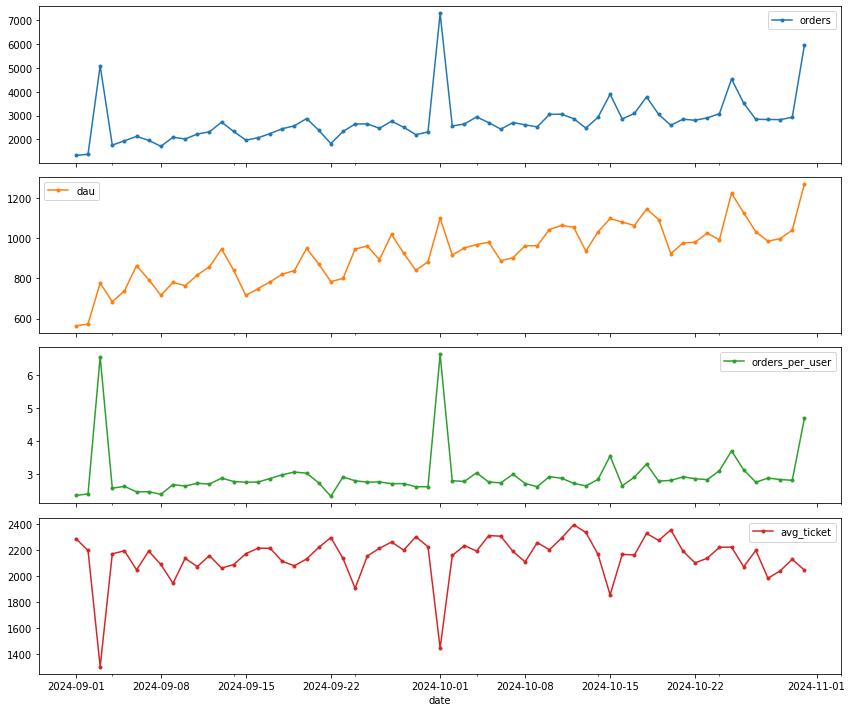

In [36]:
# Графики по дням
daily[['orders','dau','orders_per_user','avg_ticket']].plot(
    subplots=True, figsize=(12, 10), marker='o', ms=3
)
plt.tight_layout()
plt.show()

Средние показатели по дням недели — через суточные данные

,orders,dau,avg_ticket
Пн,2389.00,853.33,2140.06
Вт,3493.00,934.11,1901.57
Ср,2540.11,923.00,2152.51
Чт,3013.11,960.89,2169.38
Пт,3101.62,1022.38,2193.94
Сб,2666.38,960.50,2220.61
Вс,2152.89,822.00,2262.28


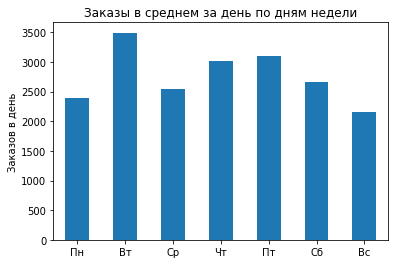

In [37]:
order_wd = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
wd_ru = {'Monday':'Пн','Tuesday':'Вт','Wednesday':'Ср','Thursday':'Чт',
         'Friday':'Пт','Saturday':'Сб','Sunday':'Вс'}

daily['weekday'] = pd.to_datetime(daily.index).day_name()

by_wd = daily.groupby('weekday')[['orders','dau','avg_ticket']].mean().reindex(order_wd)
by_wd.index = [wd_ru[d] for d in by_wd.index]

display(by_wd.round(2))

by_wd['orders'].plot(kind='bar', title='Заказы в среднем за день по дням недели')
plt.ylabel('Заказов в день')
plt.xticks(rotation=0)
plt.show()

Вторник — день для промо и массовых акций: аудитория привыкла к скидкам

Пятница — момент для рекомендаций: максимум пользователей онлайн

Сб–Вс — время премиум-предложений: аудитория готова платить больше

In [38]:
daily['is_weekend'] = pd.to_datetime(daily.index).weekday >= 5

wk = daily.groupby('is_weekend')[['orders', 'dau', 'avg_ticket']].mean()
wk.index = ['Будни', 'Выходные']

display(wk.round(2))

,orders,dau,avg_ticket
Будни,2902.95,936.84,2109.62
Выходные,2394.53,887.18,2242.67


Осенний рост заказов обеспечивается притоком новых пользователей и регулярными вторничными акциями. Аудитория распределена по неделе неравномерно: вторник — объём, пятница — охват, выходные — маржа. Разные стратегии по дням недели работают лучше универсального подхода. Риск — сильная зависимость от акций: без них объём может просесть. Стоит развивать премиум-сегмент (Сб–Вс) и лояльность (Пт), чтобы снизить эту зависимость.

### Популярные события и партнёры

In [39]:
by_region = df.groupby('region_name').agg(
    events=('event_id', 'nunique'),
    orders=('order_id', 'count'),
    revenue_rub=('revenue_rub', 'sum')
).sort_values('orders', ascending=False)

by_region['orders_share'] = by_region['orders'] / by_region['orders'].sum()

display(by_region.head(15))

,events,orders,revenue_rub,orders_share
region_name,,,,
Каменевский регион,5935,89660,5.590813e+07,0.312015
Североярская область,3798,43724,2.210468e+07,0.152159
Широковская область,1225,16099,8.628149e+06,0.056024
Медовская область,503,13889,2.927507e+06,0.048333
Озернинский край,349,10405,9.554058e+06,0.036209
Светополянский округ,1068,7486,3.037800e+06,0.026051
Малиновоярский округ,165,6314,5.089834e+06,0.021973
Речиновская область,701,6265,2.630250e+06,0.021802
Солнечноземская область,521,6238,1.181056e+06,0.021708


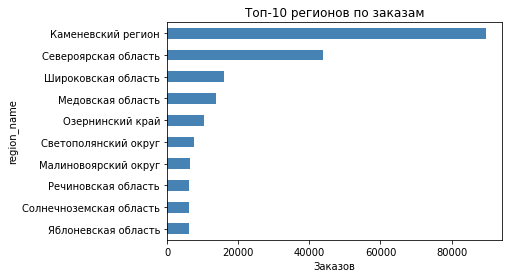

In [40]:
by_region.head(10)['orders'].plot(kind='barh', color='steelblue',
                                  title='Топ-10 регионов по заказам')
plt.xlabel('Заказов'); plt.gca().invert_yaxis(); plt.show()

Где больше всего разнообразия мероприятий:

In [41]:
by_region.sort_values('events', ascending=False).head(10)

,events,orders,revenue_rub,orders_share
region_name,,,,
Каменевский регион,5935,89660,5.590813e+07,0.312015
Североярская область,3798,43724,2.210468e+07,0.152159
Широковская область,1225,16099,8.628149e+06,0.056024
Светополянский округ,1068,7486,3.037800e+06,0.026051
Речиновская область,701,6265,2.630250e+06,0.021802
Травяная область,683,5036,1.787821e+06,0.017525
Горицветская область,551,5152,1.697461e+06,0.017929
Серебринская область,541,5586,2.106600e+06,0.019439
Яблоневская область,534,6120,3.505459e+06,0.021297


In [42]:
by_service = df.groupby('service_name').agg(
    events=('event_id', 'nunique'),
    orders=('order_id', 'count'),
    revenue_rub=('revenue_rub', 'sum')
).sort_values('revenue_rub', ascending=False)

by_service['revenue_share'] = by_service['revenue_rub'] / by_service['revenue_rub'].sum()

display(by_service.head(15))

,events,orders,revenue_rub,revenue_share
service_name,,,,
Билеты без проблем,4218,62820,2.432247e+07,0.162954
Мой билет,1302,34442,2.204215e+07,0.147677
Облачко,2335,26402,1.858861e+07,0.124539
Лови билет!,4861,40766,1.667416e+07,0.111713
Весь в билетах,855,16424,1.653235e+07,0.110763
Билеты в руки,3523,40205,1.319650e+07,0.088413
Край билетов,252,6109,6.405689e+06,0.042917
Прачечная,1026,10222,4.746811e+06,0.031802
Дом культуры,272,4412,4.358656e+06,0.029202


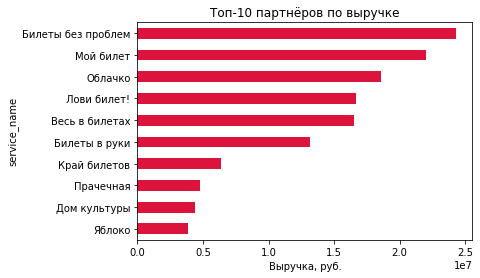

In [43]:
by_service.head(10)['revenue_rub'].plot(kind='barh', color='crimson',
                                        title='Топ-10 партнёров по выручке')
plt.xlabel('Выручка, руб.'); plt.gca().invert_yaxis(); plt.show()

Регионы.

Лидеры: Каменевский региони Североярская область. Вместе — почти половина всех заказов.

Топ-10 регионов дают ≈85% заказов, топ-15 — ≈92%. Остальные — длинный хвост с минимальным вкладом.

Порядок регионов по числу заказов, выручке и разнообразию мероприятий почти совпадает — где плотнее афиша, там и больше покупок.

Партнёры

Шесть партнёров дают ≈75% выручки: «Билеты без проблем», «Мой билет», «Облачко», «Лови билет!», «Весь в билетах», «Билеты в руки» 

Стратегии разные: у «Лови билет!» — максимум событий и заказов, но ниже средний чек; у «Весь в билетах» и «Мой билет» — мало событий, но высокий чек. «Билеты без проблем» — лидер по всем метрикам сразу.

## Статистический анализ данных

Две гипотезы:

1. Число заказов на пользователя у mobile больше, чем у desktop.

2. Интервал между заказами у mobile больше, чем у desktop.

Особенность данных: один пользователь может заказывать и с телефона, и с компьютера — это нарушает независимость выборок.

Подготовка данных - только осень:

In [44]:
autumn = df[df['season'] == 'осень'].copy()
display('Осенних заказов:', len(autumn))
display('Устройства:', autumn['device_type_canonical'].value_counts())

'Осенних заказов:'

168437

'Устройства:'

mobile     134141
desktop     34296
Name: device_type_canonical, dtype: int64

Гипотезы  

H0: среднее число заказов с mobile не больше, чем с desktop (разность ≤ 0).

H1: среднее число заказов с mobile больше, чем с desktop (разность > 0).

для каждого пользователя — заказы с mobile и desktop

In [45]:
pivot = (autumn.groupby(['user_id', 'device_type_canonical'])
         .size().unstack(fill_value=0))

display(pivot.head())

display('Всего пользователей:', len(pivot))
display('Только mobile:',
        ((pivot['mobile'] > 0) & (pivot['desktop'] == 0)).sum())
display('Только desktop:',
        ((pivot['mobile'] == 0) & (pivot['desktop'] > 0)).sum())
display('Смешанные (оба устройства):',
        ((pivot['mobile'] > 0) & (pivot['desktop'] > 0)).sum())

device_type_canonical,desktop,mobile
user_id,,
0005ca5e93f2cf4,0,1
000898990054619,0,2
000a55a418c128c,0,2
001e7037d013f0f,0,2
00245c702bc343e,0,2


'Всего пользователей:'

15804

'Только mobile:'

10935

'Только desktop:'

1618

'Смешанные (оба устройства):'

3251

In [46]:
diff = pivot['mobile'] - pivot['desktop']

display(f'Средняя разность mobile − desktop: {diff.mean():.3f}')
display(f'Медиана разности: {diff.median()}')
display(f'Доля пользователей с перевесом mobile: {(diff > 0).mean():.2%}')

t, p_t = ttest_rel(pivot['mobile'], pivot['desktop'], alternative='greater')
display(f'Парный t-тест: t = {t:.3f}, p = {p_t:.4g}')

'Средняя разность mobile − desktop: 6.318'

'Медиана разности: 1.0'

'Доля пользователей с перевесом mobile: 83.76%'

'Парный t-тест: t = 16.784, p = 5.613e-63'

Гипотеза 1 подтверждена.H0 отклоняется, у мобильных пользователей значимо больше заказов, чем у стационарных.

Гипотеза 2. Интервал между заказами: mobile > desktop

Постановка

H0: распределение средних интервалов между заказами у mobile не смещено правее относительно desktop.

H1: у mobile интервал больше (пользователи возвращаются реже).

Для сравнения двух независимых выборок выбираем непараметрический тест Манна–Уитни, который не требует нормальности и устойчив к выбросам.

In [47]:
user_gap = (autumn.groupby('user_id')
            .agg(avg_gap=('days_since_prev', 'mean'))
            .dropna())

# тип пользователя по устройству
user_type = (autumn.groupby('user_id')['device_type_canonical']
             .agg(lambda s: 'mobile' if (s == 'mobile').all()
                            else 'desktop' if (s == 'desktop').all()
                            else 'mixed'))

user_df = user_gap.join(user_type)
display(user_df.head())

display('Только mobile:', (user_df['device_type_canonical'] == 'mobile').sum())
display('Только desktop:', (user_df['device_type_canonical'] == 'desktop').sum())
display('Смешанные (исключаем):', (user_df['device_type_canonical'] == 'mixed').sum())

,avg_gap,device_type_canonical
user_id,,
0005ca5e93f2cf4,75.0,mobile
000898990054619,51.0,mobile
000a55a418c128c,16.0,mobile
001e7037d013f0f,43.5,mobile
00245c702bc343e,27.5,mobile


'Только mobile:'

7050

'Только desktop:'

893

'Смешанные (исключаем):'

3251

In [48]:
m = user_df[user_df['device_type_canonical'] == 'mobile']['avg_gap']
d = user_df[user_df['device_type_canonical'] == 'desktop']['avg_gap']

display(f'mobile : n = {len(m)}, mean = {m.mean():.3f}, median = {m.median():.3f}')
display(f'desktop: n = {len(d)}, mean = {d.mean():.3f}, median = {d.median():.3f}')

u, p_mw = mannwhitneyu(m, d, alternative='greater')
display(f'Манн–Уитни (односторонний): U = {u:.1f}, p = {p_mw:.4g}')

'mobile : n = 7050, mean = 25.262, median = 14.000'

'desktop: n = 893, mean = 31.356, median = 16.000'

'Манн–Уитни (односторонний): U = 3097690.0, p = 0.7822'

Гипотеза 2 не подтверждена. Нет оснований утверждать, что у mobile пауза между заказами больше, чем у desktop.

Более того, данные показывают обратную тенденцию: у mobile средняя пауза меньше (25,3 дня vs 31,8 у desktop), медиана — 14 vs 16 дней. Это означает, что мобильные пользователи возвращаются чаще, а не реже.

Вывод: мобильные пользователи активнее — они и заказывают больше (гипотеза 1 подтверждена), и возвращаются быстрее (данные гипотезы 2). Это согласуется с продуктовой гипотезой о большей активности мобильной аудитории.

## Общий вывод и рекомендации

О данных

Работали с тремя датасетами Яндекс Афиши за июнь–октябрь 2024: заказы (290 849), мероприятия (22 427) и курс тенге (357). После предобработки: даты приведены к datetime, удалены отрицательная выручка, выбросы revenue по 99-му перцентилю раздельно по rub и kzt и неявные дубликаты. Валюта приведена к рублю (revenue_rub), созданы one_ticket_revenue_rub, month, season. Осталось ~283 тыс. заказов (потери ≈2–3%).

Осенью сервис растёт в объёме, но не в деньгах на пользователя. Число заказов увеличивается почти в 3 раза от июня к октябрю, но средняя цена билета падает. Это не противоречие, а следствие смены структуры спроса:

 - Меняется афиша. Летом — концерты и фестивали, осенью — театр, спорт и семейные события. Спорт вырос в несколько раз.

 - Приходит новая аудитория. Число заказов и DAU растут синхронно, но  среднее число заказов на одного активного пользователя стабильно — рост обеспечивается притоком новых пользователей, а не частотой покупок.

 - Новые пользователи выбирают дешёвые сегменты. Поэтому общий средний чек в основном падает.

 - Мобильный канал доминирует — 80% заказов, и статистически подтверждено, что mobile активнее: делает больше заказов и возвращается чаще.

Общая картина: сервис переживает сезонную трансформацию аудитории. Осенью приходит много новых пользователей через мобильные устройства, но их средний чек ниже. Рост выручки идёт за счёт объёма, а не цены.

Топ-2 региона дают почти половину заказов, топ-10 — 85%. Лидер — Каменевский регион.

Топ-6 партнёров дают большую часть выручки. «Билеты без проблем» — лидер по всем метрикам.

Такая концентрация является риском, сейчас сервис сильно зависит от нескольких точек. Длинный хвост регионов и партнёров (десятки позиций с долей <1%) — недоиспользованный потенциал, за счет них можно снизить зависимость и расширить охват.

Рекомендации

1. Мобильный сценарий — приоритет №1

2. Удержать топ-партнёров и топ-регион
    Реализация: индивидуальные условия, раннее предупреждение оттока, ежемесячный мониторинг метрик, приоритетная поддержка.

3. Развивать «второй эшелон» регионов и партнёров
    Если поддерживать только топ, доля на рынке не вырастет — просто закрепимся в существующих точках. Остальные регионы не разовьются, а мы потеряем потенциал роста.

    Как реализовать: Инвестировать в регионы такие как Широковская, Медовская, Озернинский край. Маркетинг, адаптация афиши, поддержка.

    Как результат: снижение зависимости от лидеров и расширение охвата.

4. Работать со средним чеком
    Средний чек падает, потому что новая аудитория выбирает дешёвые сегменты, может снизиться маржинальность.

5. Учесть специфику выходных
    Акции лучше работают в начале недели, когда спрос низкий.

    Как реализовать: разные стратегии по дням:

        Вторник — промо и акции (там уже привыкли к скидкам)

        Пятница — рекомендации и апселл (максимум пользователей).

        Сб–Вс — премиум-предложения, не скидки (аудитория готова платить больше).

    Как результат получим оптимальное использование каждого дня недели.

6. Специфика партнёров — не универсальная
    Разные партнёры имеют разные бизнес-модели. «Лови билет!» — масса дешёвых билетов, «Весь в билетах» и «Мой билет» — премиум с высоким чеком. Кейсы одних не подойдут другим.

    Как реализовать: индивидуальные стратегии: массовым — объём и охват, премиум — качество и маржинальность. Оценить, сколько у нас власти над партнёрами — это влияет на реалистичность рекомендаций.


